# Deliverable 1: modeling the delivery routing problem

**CesiCDP for the ADEME Smart Multimodal Mobility call.** Team: Pablo, Dag, Farida.
Owner of this notebook: Person 1 (modeling and exact methods).

This notebook is the **modeling deliverable** checked with the tutor during Prosit 3. It tells the
story of how we went from a business question ("deliver with fewer kilometres") to a mathematical
model we trust. It is written so that someone who did not attend our meetings can follow every
decision.

**The path we follow**

| Step | Question we answer | Section |
| --- | --- | --- |
| 1 | What is the problem, and why does it matter? | 1 |
| 2 | Which data does the problem need, and where do we get it? | 2 |
| 3 | How do we write that data and the problem in mathematics? | 3, 4 |
| 4 | Which realistic constraint do we add? | 5 |
| 5 | How hard is the problem? (complexity proof) | 6 |
| 6 | How can we write it as an integer linear program? We found three ways: A, B and C | 7 |
| 7 | Which of A, B, C is best? We test them on the same instances | 8 |
| 8 | Comparison of the results and our choice | 9 |
| 9 | Does the model still work with time windows? | 10 |
| 10 | Conclusion: what we deliver, what we learned, what comes next | 11 |

**Scope.** This deliverable is about the **model**. We do use a solver, but only to *validate*
the model (does it return correct, feasible routes?) and to *compare formulations*. The solution
method for realistic sizes, a metaheuristic, is the subject of the next deliverable.

## 1. The problem and why it matters

**The call.** ADEME, the French Environment and Energy Management Agency, has opened a call for
pilot projects on *Smart Multimodal Mobility*: mobility solutions for people and goods that use
less energy and emit less. CesiCDP, already active in smart mobility, answers on one theme:
**delivery route management**.

**Why routes matter for the climate.** The Kyoto Protocol (signed 1997, in force 2005) and the
Paris Agreement (2015) committed countries to cut greenhouse gas emissions, and transport, in
particular road freight, is one of the largest emitting sectors. Logistics is a direct lever: the
same deliveries done with fewer kilometres and fewer trucks mean less fuel or electricity burnt,
with no change asked of the customers. Every percent removed from the total route duration is
saved again on every working day of every truck.

**The question CesiCDP must answer.** A company has one depot, a fleet of identical trucks and a
list of customers to deliver today. *Which truck visits which customers, in which order, so that
all deliveries are made and the total driving time is as small as possible?*

The brief adds realistic constraints: trucks have a **capacity** (Level B of the project, the
*Capacitated Vehicle Routing Problem*, CVRP) and customers can only be served inside a **time
window** (Level A, the CVRPTW). Traffic varying during the day is mentioned as an extension.

## 2. Which data does the problem need?

Before writing any equation we listed what the question above needs to be answered, and turned
each element into a piece of data:

| What the business question mentions | Data we need | Symbol (section 3) |
| --- | --- | --- |
| "a depot", "customers" | a list of locations, one of them the depot | $V = \{0, \dots, n\}$ |
| "driving time" between places | a travel time for every ordered pair of locations | $c_{ij}$ |
| "deliver" a quantity to each customer | the demand of each customer | $q_i$ |
| "identical trucks" with a limit | the capacity of a truck and the size of the fleet | $Q$, $K$ |
| "only between 9:00 and 11:00" (Level A) | an opening window and a service duration per customer | $[e_i, l_i]$, $s_i$ |

**Where the data comes from.** CesiCDP has no client data yet, and a model must be checked
against problems whose answer is known. So we use the **standard public benchmarks** of the
vehicle routing literature. They contain exactly the data above, and their best known (often
proven optimal) solutions are published, which lets us check our model:

| Set | Why we use it | Customers | Source |
| --- | --- | --- | --- |
| Augerat **A** (`A-n32-k5`) | customers spread **at random**, like deliveries in a city | 31 | CVRPLIB |
| Augerat **B** (`B-n31-k5`) | customers in **clusters**, like neighbourhoods or villages | 30 | CVRPLIB |
| Augerat **P** (6 instances) | small *complete* instances with a proven optimum, to validate the model | 15 to 21 | CVRPLIB |
| Solomon **C101** | the reference set **with time windows** (Level A) | 100 | Solomon (1987) |

Instances are downloaded, not committed: see `data/README.md` for the exact URLs and the folder
layout. The block below loads them with the project's `Instance.from_vrplib` (built on the
`vrplib` package).

In [1]:
import math
import sys
from itertools import permutations
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))  # works without `pip install -e .`

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cvrp import Instance, Solution
from cvrp.ilp import solve_cvrp_flow, solve_cvrp_mtz, solve_cvrp_rcc, solve_cvrptw
from cvrp.timewindows import is_route_tw_feasible, route_schedule
from cvrp.viz import plot_routes

pd.set_option("display.precision", 2)
DATA = ROOT / "data"

In [2]:
def load(set_name: str, name: str) -> Instance:
    # Load a CVRPLIB instance and its best known solution (the .sol file next to it).
    folder = DATA / "cvrplib" / set_name
    vrp, sol = folder / f"{name}.vrp", folder / f"{name}.sol"
    if not vrp.exists():
        raise FileNotFoundError(f"{vrp} is missing: download it as explained in data/README.md")
    return Instance.from_vrplib(vrp, sol)


A = load("A", "A-n32-k5")
B = load("B", "B-n31-k5")
P_NAMES = ["P-n16-k8", "P-n19-k2", "P-n20-k2", "P-n21-k2", "P-n22-k2", "P-n22-k8"]
P = [load("P", name) for name in P_NAMES]
C101 = Instance.from_vrplib(DATA / "solomon" / "C101.txt", DATA / "solomon" / "C101.sol",
                            instance_format="solomon")


def describe(inst: Instance) -> dict:
    # One line of facts about an instance: size, capacity and how tight the capacity is.
    k_min = inst.lower_bound_vehicles
    return {
        "instance": inst.name,
        "customers n": inst.n_customers,
        "capacity Q": inst.capacity,
        "fleet K": inst.num_vehicles,
        "total demand": inst.demands.sum(),
        "min trucks": k_min,
        "fill rate %": 100 * inst.demands.sum() / (k_min * inst.capacity),
        "customers per truck": inst.n_customers / k_min,
        "time windows": inst.has_time_windows,
        "best known": inst.best_known,
    }


pd.DataFrame([describe(i) for i in [A, B, *P, C101]]).set_index("instance")

,customers n,capacity Q,fleet K,total demand,min trucks,fill rate %,customers per truck,time windows,best known
instance,,,,,,,,,
A-n32-k5,31,100.0,5,410.0,5,82.00,6.20,False,784.0
B-n31-k5,30,100.0,5,412.0,5,82.40,6.00,False,672.0
P-n16-k8,15,35.0,8,246.0,8,87.86,1.88,False,450.0
P-n19-k2,18,160.0,2,310.0,2,96.88,9.00,False,212.0
P-n20-k2,19,160.0,2,310.0,2,96.88,9.50,False,216.0
P-n21-k2,20,160.0,2,298.0,2,93.12,10.00,False,211.0
P-n22-k2,21,160.0,2,308.0,2,96.25,10.50,False,216.0
P-n22-k8,21,3000.0,8,22500.0,8,93.75,2.62,False,603.0
C101,100,200.0,25,1810.0,10,90.50,10.00,True,827.3


*How to read the table.* "min trucks" is $\lceil \sum_i q_i / Q \rceil$: no solution can use
fewer trucks. The "fill rate" says how full those trucks would be, and "customers per truck" how
long the routes are. Two P instances stand out: `P-n16-k8` and `P-n22-k8` need **8 trucks for
only 2 to 3 customers each**, with trucks about 90 percent full. There, deciding *which customers
share a truck* (a packing puzzle) matters as much as the order of visits. We will see in section 9
that this is exactly where one of our formulations struggles.

*About C101.* The published value 827.3 was computed with distances truncated to one decimal.
We keep exact Euclidean distances, under which the commonly reported optimum is 828.94; section 10
checks that we find it.

The three families look very different on a map:

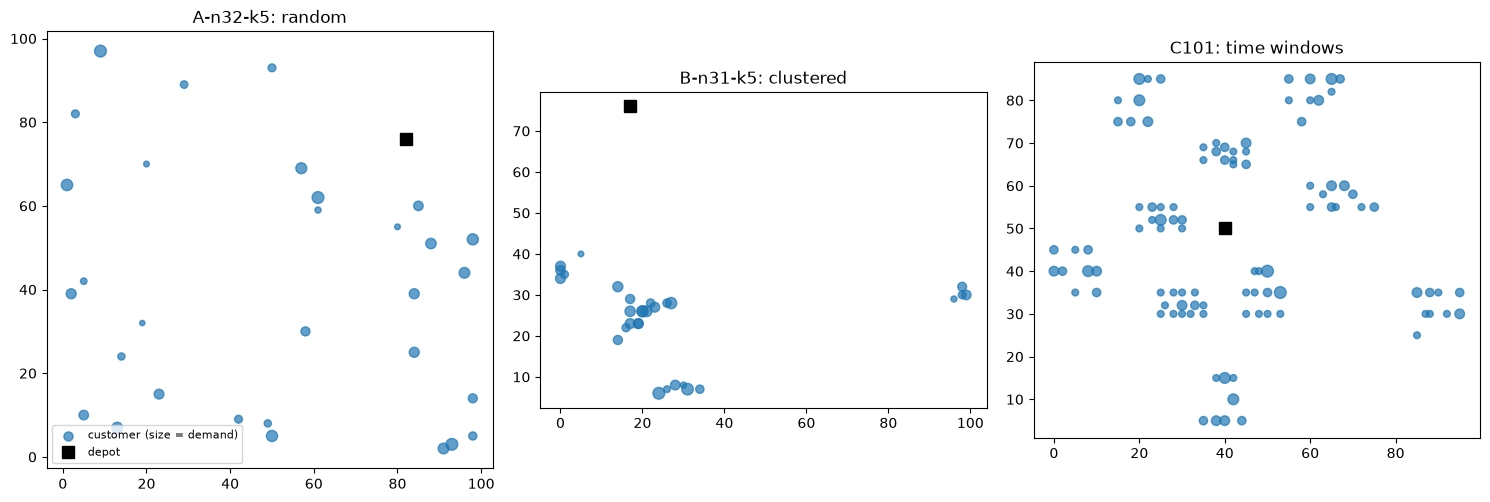

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, inst, title in zip(axes, [A, B, C101],
                           ["A-n32-k5: random", "B-n31-k5: clustered", "C101: time windows"]):
    ax.scatter(*inst.coords[1:].T, s=12 + 60 * inst.demands[1:] / inst.demands.max(),
               alpha=0.7, label="customer (size = demand)")
    ax.plot(*inst.coords[0], "ks", ms=9, label="depot")
    ax.set_title(title)
    ax.set_aspect("equal")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

**Smaller versions for the exact study.** An exact method cannot be expected to solve 30 or 100
customers quickly (section 6 explains why). To watch how each formulation behaves as the problem
grows, we also cut the A and B instances to their **first $n$ customers**, for
$n = 6, 8, \dots, 16$. The capacity is kept, and the fleet is left free ($K = n$), so these
smaller problems stay meaningful.

In [4]:
def truncate(inst: Instance, n: int) -> Instance:
    # Keep the depot and the first n customers of an instance (fleet left free).
    keep = slice(0, n + 1)
    tw = inst.has_time_windows
    return Instance(
        name=f"{inst.name}[:{n}]",
        coords=inst.coords[keep],
        demands=inst.demands[keep],
        capacity=inst.capacity,
        num_vehicles=None,
        ready_times=inst.ready_times[keep] if tw else None,
        due_times=inst.due_times[keep] if tw else None,
        service_times=inst.service_times[keep] if inst.service_times is not None else None,
        dist=inst.dist[keep, keep],
    )


SIZES = [6, 8, 10, 12, 14, 16]
benchmark = (
    [("A (random)", truncate(A, n)) for n in SIZES]
    + [("B (clustered)", truncate(B, n)) for n in SIZES]
    + [("P (full)", inst) for inst in P]
)
print(f"{len(benchmark)} instances, n from {min(i.n_customers for _, i in benchmark)} "
      f"to {max(i.n_customers for _, i in benchmark)} customers")

18 instances, n from 6 to 21 customers


## 3. Writing the data in mathematics

**From a road network to a complete graph.** A real road network is a sparse graph of streets.
We replace it by the **complete directed graph** $G = (V, A)$ whose arc cost $c_{ij}$ is the
duration of the fastest path from $i$ to $j$ in the network (computed once, for example with
Dijkstra's algorithm). Two consequences:

1. The costs satisfy the **triangle inequality** $c_{ij} \le c_{ik} + c_{kj}$, so a route never
   gains by passing through a customer twice. We can therefore require each customer to be
   visited exactly once.
2. In the benchmarks, $c_{ij}$ is the Euclidean distance between coordinates (rounded to the
   nearest integer for CVRPLIB, exact for Solomon). This amounts to a constant speed: duration
   and distance coincide.

| Symbol | Meaning | In the code (`cvrp.Instance`) |
| --- | --- | --- |
| $V = \{0, 1, \dots, n\}$ | nodes; $0$ is the depot | indices of `coords` |
| $V^+ = V \setminus \{0\}$ | customers, $\lvert V^+ \rvert = n$ | `n_customers` |
| $A = \{(i, j) \in V^2 : i \neq j\}$ | arcs of the complete directed graph | |
| $c_{ij} \ge 0$ | travel time from $i$ to $j$ | `dist[i, j]` |
| $q_i > 0$ | demand of customer $i$, $q_0 = 0$, $q_i \le Q$ | `demands` |
| $Q$ | capacity of every truck (homogeneous fleet) | `capacity` |
| $K$ | number of available trucks | `num_vehicles` |
| $[e_i, l_i]$ | time window of node $i$ (Level A); $[e_0, l_0]$ is the working day | `ready_times`, `due_times` |
| $s_i \ge 0$ | service time at node $i$ (Level A), $s_0 = 0$ | `service_times` |

To make the notation concrete, here is a **toy instance** small enough to check by hand: six
customers around a depot at the origin, $Q = 10$, $K = 3$. We use it again in section 4 to show a
solution and in section 8 to check the solver against brute force.

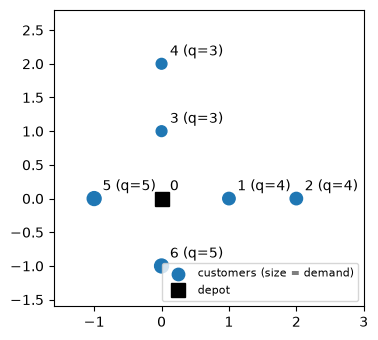

travel times c_ij (rounded):
[[0.   1.   2.   1.   2.   1.   1.  ]
 [1.   0.   1.   1.41 2.24 2.   1.41]
 [2.   1.   0.   2.24 2.83 3.   2.24]
 [1.   1.41 2.24 0.   1.   1.41 2.  ]
 [2.   2.24 2.83 1.   0.   2.24 3.  ]
 [1.   2.   3.   1.41 2.24 0.   1.41]
 [1.   1.41 2.24 2.   3.   1.41 0.  ]]


In [5]:
coords = np.array([[0, 0], [1, 0], [2, 0], [0, 1], [0, 2], [-1, 0], [0, -1]], dtype=float)
demands = np.array([0, 4, 4, 3, 3, 5, 5], dtype=float)
toy = Instance(name="toy", coords=coords, demands=demands, capacity=10, num_vehicles=3)

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(*coords[1:].T, s=demands[1:] * 20, label="customers (size = demand)")
ax.plot(*coords[0], "ks", ms=10, label="depot")
for i, (x, y) in enumerate(coords):
    ax.annotate(f"{i} (q={demands[i]:.0f})" if i else "0", (x, y), textcoords="offset points",
                xytext=(6, 6))
ax.set_aspect("equal"); ax.set_xlim(-1.6, 3); ax.set_ylim(-1.6, 2.8)
ax.legend(loc="lower right", fontsize=8); plt.show()
print("travel times c_ij (rounded):")
print(np.round(toy.dist, 2))

## 4. The problem and its objective

**In words.** Using at most $K$ trucks of capacity $Q$, all starting and ending at the depot,
serve every customer exactly once without overloading any truck, so that the total travel time is
minimal.

**Formally.** A **route** is a sequence $r = (0, v_1, \dots, v_m, 0)$ of distinct customers. Its
load and its cost are

$$
q(r) = \sum_{t=1}^{m} q_{v_t},
\qquad
c(r) = c_{0 v_1} + \sum_{t=1}^{m-1} c_{v_t v_{t+1}} + c_{v_m 0}.
$$

A **feasible solution** is a set of routes $\{r_1, \dots, r_p\}$ with $p \le K$, such that every
customer appears in exactly one route and $q(r_k) \le Q$ for every $k$. Writing $\mathcal{S}$ for
the set of feasible solutions, the **CVRP** is

$$
\min_{\{r_1, \dots, r_p\} \in \mathcal{S}} \ \sum_{k=1}^{p} c(r_k).
$$

**Modeling choices we made.**

- **Fleet.** $K$ is an *upper bound* given by the instance, not a number of routes we must use.
  Any feasible solution needs at least $\lceil \sum_i q_i / Q \rceil$ trucks (the "min trucks"
  column of section 2).
- **Objective.** Total travel time. Since $c_{ij}$ is a duration, minimizing time and minimizing
  distance are the same thing in the base model, and fewer kilometres means fewer emissions.
- **Traffic per time slot (extension, kept out of the base model).** With traffic, the cost of an
  arc depends on the departure time: $c_{ij}$ becomes $c_{ij}(t)$. The standard way to keep it
  consistent (a truck that leaves later never arrives earlier, the FIFO property) is to make
  *speeds* piecewise constant over time slots (Ichoua, Gendreau and Potvin, 2003). The cost of a
  route then depends on the order *and* on departure times, which is why we treat it as a later
  improvement.

**Worked example on the toy instance.** The total demand is 24 and $Q = 10$, so at least
$\lceil 24 / 10 \rceil = 3$ trucks are needed: here, the whole fleet. Grouping neighbouring
customers gives a feasible solution (section 8 shows it is in fact optimal):

In [6]:
toy_solution = Solution([[1, 2], [3, 4], [5, 6]])
for r in toy_solution.routes:
    print(f"route 0 -> {' -> '.join(map(str, r))} -> 0 | load {toy.demands[r].sum():.0f} / 10")
print(f"total cost: {toy_solution.cost(toy):.3f}")
print("violated constraints:", toy_solution.violations(toy) or "none, the solution is feasible")

route 0 -> 1 -> 2 -> 0 | load 8 / 10
route 0 -> 3 -> 4 -> 0 | load 6 / 10
route 0 -> 5 -> 6 -> 0 | load 10 / 10
total cost: 11.414
violated constraints: none, the solution is feasible


## 5. The additional constraint we chose: time windows (Level A)

Real customers are not available all day: a shop receives goods before opening, an office only
during working hours. So we add **time windows**. Each node $i$ has a window $[e_i, l_i]$ and a
service time $s_i$. A truck **may arrive early and wait** until $e_i$, but service can never start
after $l_i$. The depot window $[e_0, l_0]$ is the working day: trucks leave at $e_0$ at the
earliest and must be back by $l_0$.

Along a route $(0, v_1, \dots, v_m, 0)$, write $a_{v_t}$ for the arrival time and $b_{v_t}$ for
the service start:

$$
b_0 = e_0, \qquad
a_{v_t} = b_{v_{t-1}} + s_{v_{t-1}} + c_{v_{t-1} v_t}, \qquad
b_{v_t} = \max(a_{v_t},\ e_{v_t}).
$$

The route is feasible when $b_{v_t} \le l_{v_t}$ for every visited node, including the return to
the depot. The waiting time is $w_{v_t} = b_{v_t} - a_{v_t} \ge 0$. The **CVRPTW** is the CVRP of
section 4 in which every route must also satisfy these window constraints.

**Objective at Level A.** Unchanged: total travel time. Waiting is allowed but not counted, which
keeps the model comparable with the CVRP and with the Solomon benchmarks. Counting waiting (that
is, minimizing the total *duration* of the routes) is the natural variant if drivers are paid by
the hour; *to confirm with the tutor.*

Example on the toy instance with a window $[3, 5]$ on customer 1, which forces the truck to wait:

In [7]:
ready = np.array([0, 3, 0, 0, 0, 0, 0], dtype=float)       # e_i
due = np.array([20, 5, 10, 10, 10, 10, 10], dtype=float)    # l_i; the working day is [0, 20]
service = np.array([0, 1, 1, 1, 1, 1, 1], dtype=float)      # s_i
toy_tw = Instance(name="toy_tw", coords=coords, demands=demands, capacity=10, num_vehicles=3,
                  ready_times=ready, due_times=due, service_times=service)

route = [1, 2]
sched = route_schedule(route, toy_tw)
print("node  window     arrival  start  wait")
for k, i in enumerate([0, *route, 0]):
    print(f"{i:>4}  [{ready[i]:>3.0f},{due[i]:>3.0f}]  {sched['arrival'][k]:>7.2f}  "
          f"{sched['start'][k]:>5.2f}  {sched['wait'][k]:>4.2f}")

node  window     arrival  start  wait
   0  [  0, 20]     0.00   0.00  0.00
   1  [  3,  5]     1.00   3.00  2.00
   2  [  0, 10]     5.00   5.00  0.00
   0  [  0, 20]     8.00   8.00  0.00


The truck reaches customer 1 at time 1, waits 2 units for the window to open, serves it from 3 to
4, and still reaches customer 2 (window $[0, 10]$) on time.

## 6. How hard is the problem? Complexity proof

Before choosing a method we need to know whether a fast exact algorithm can exist. A first hint:
even if we ignore capacity, one truck visiting $n$ customers can do so in $n!$ orders.

In [8]:
for n in [5, 10, 15, 20, 30]:
    orders = float(math.factorial(n))
    print(f"n = {n:>2}: {orders:.2e} visiting orders "
          f"({orders / 1e9 / 3600 / 24 / 365:.1e} years at a billion orders per second)")

n =  5: 1.20e+02 visiting orders (3.8e-15 years at a billion orders per second)
n = 10: 3.63e+06 visiting orders (1.2e-10 years at a billion orders per second)
n = 15: 1.31e+12 visiting orders (4.1e-05 years at a billion orders per second)
n = 20: 2.43e+18 visiting orders (7.7e+01 years at a billion orders per second)
n = 30: 2.65e+32 visiting orders (8.4e+15 years at a billion orders per second)


Counting is not a proof: a clever algorithm might avoid looking at every order. The proof below
shows that, unless P = NP, **no** algorithm can solve every instance in polynomial time.

**Goal.** Show that the CVRP, and then the CVRPTW, are NP-hard, by a chain of polynomial
reductions from a problem known to be NP-complete:

$$
\text{Hamiltonian cycle} \ \le_p\ \text{TSP-DEC} \ \le_p\ \text{CVRP-DEC} \ \le_p\ \text{CVRPTW-DEC}.
$$

We work with **decision versions**. **CVRP-DEC**: given an instance $(G, c, q, Q, K)$ and a bound
$B$, is there a feasible solution of cost at most $B$? **TSP-DEC**: given a complete graph with
costs $c$ and a bound $B$, is there a tour visiting every node exactly once with cost at most $B$?
**Hamiltonian cycle (HC)**: given an undirected graph $H$, does it have a cycle through every
vertex exactly once? HC is NP-complete (Karp, 1972).

### Step 1: CVRP-DEC is in NP

A certificate is a list of routes. Given it, we check in polynomial time that:

- every customer of $V^+$ appears exactly once over all routes (one counting pass, $O(n)$);
- each route load is at most $Q$ and there are at most $K$ routes ($O(n)$);
- the total cost, a sum of $n + p \le 2n$ arc costs, is at most $B$ ($O(n)$).

The certificate has size $O(n)$, so CVRP-DEC $\in$ NP. (`Solution.violations` performs exactly
these checks.) Adding the computation of $a$ and $b$ along each route, also $O(n)$, shows that
CVRPTW-DEC $\in$ NP.

### Step 2: HC reduces to TSP-DEC

Given $H = (V_H, E)$ with $\lvert V_H \rvert = N$, build the complete graph on $V_H$ with

$$
c_{ij} = \begin{cases} 1 & \text{if } \{i, j\} \in E, \\ 2 & \text{otherwise,} \end{cases}
\qquad B = N.
$$

The construction takes $O(N^2)$ time.

- ($\Rightarrow$) If $H$ has a Hamiltonian cycle, the same cycle is a tour that uses only edges of
  $E$: its $N$ arcs cost 1 each, so its cost is $N \le B$.
- ($\Leftarrow$) If there is a tour of cost at most $N$: it has exactly $N$ arcs, each of cost at
  least 1, so every arc costs exactly 1, i.e. every arc is an edge of $E$. The tour is a
  Hamiltonian cycle of $H$.

So $H$ has a Hamiltonian cycle if and only if the TSP instance is a yes instance. TSP-DEC is in NP
(same certificate argument as step 1), hence TSP-DEC is NP-complete.

### Step 3: TSP-DEC reduces to CVRP-DEC

Given a TSP instance on nodes $\{0, 1, \dots, n\}$ with costs $c$ and bound $B$, build the CVRP
instance with the same graph and costs, node $0$ as the depot, and

$$
q_i = 1 \ \ \forall i \in V^+, \qquad Q = n, \qquad K = 1, \qquad \text{same } B.
$$

The construction is linear in the size of the input.

- ($\Rightarrow$) A tour of cost at most $B$ visits every node once; rotate it so it starts at
  $0$. It is a single route through all customers with load $n = Q$: a feasible CVRP solution of
  the same cost.
- ($\Leftarrow$) With $K = 1$, a feasible CVRP solution is a single route $(0, v_1, \dots, v_n, 0)$
  visiting every customer exactly once: it is a tour of the TSP instance, with the same cost.

Hence CVRP-DEC is NP-complete, and the optimization CVRP is **NP-hard**: a polynomial algorithm
for it would decide HC in polynomial time, so P = NP.

*Remark.* The reduction also works when $K$ is left free ($K = n$): with $Q \ge \sum_i q_i$ and
the triangle inequality (which holds in the instance of step 2, costs being 1 or 2), merging two
routes $(0, \dots, a, 0)$ and $(0, b, \dots, 0)$ into one by replacing $a \to 0 \to b$ with
$a \to b$ never increases the cost, so an optimal solution uses one route. This also answers the
class hypothesis "the solution is a Hamiltonian cycle": it is true only when one truck suffices;
in general a solution is a set of cycles that share the depot and partition the customers.

### Step 4: CVRPTW is NP-hard

Every CVRP instance is a CVRPTW instance with $e_i = 0$, $l_i = +\infty$ (in practice, any value
larger than the sum of all costs) and $s_i = 0$: the window constraints are then always satisfied
and both problems have the same feasible solutions and costs. The CVRPTW generalizes the CVRP, so
it is NP-hard as well. A stronger result holds: with a fixed number of trucks, even *finding a
feasible* CVRPTW solution is NP-complete (Savelsbergh, 1985).

### Remark: capacity alone is already hard

Ignoring routing costs, deciding whether $K$ trucks of capacity $Q$ can carry all the demands is
the bin packing decision problem, which is strongly NP-complete (Garey and Johnson, 1979). The CVRP
is hard for two independent reasons: **routing** (TSP) and **packing** (bin packing). Section 9
shows that the second reason is visible in practice on instances with tight capacity.

### Consequence for the method

No polynomial exact algorithm exists unless P = NP. An integer linear program (next section) is
still useful: it gives **proven optimal** answers on small instances, and **lower bounds** on
larger ones, against which the future metaheuristic will be measured.

## 7. Writing the problem as an integer linear program: three candidates

### 7.1 The part every formulation shares

We use **two-index** variables: $x_{ij} \in \{0, 1\}$ for every arc $(i, j) \in A$, equal to 1 if
a truck drives directly from $i$ to $j$.

$$
\begin{aligned}
\min \ & \sum_{(i, j) \in A} c_{ij}\, x_{ij} && && \text{total travel time}\\
\text{s.t. } & \sum_{j \in V,\, j \neq i} x_{ij} = 1 && \forall i \in V^+ && \text{(1) leave each customer once}\\
& \sum_{i \in V,\, i \neq j} x_{ij} = 1 && \forall j \in V^+ && \text{(2) enter each customer once}\\
& \sum_{j \in V^+} x_{0j} \le K && && \text{(3) at most } K \text{ trucks}\\
& \sum_{j \in V^+} x_{0j} = \sum_{i \in V^+} x_{i0} && && \text{(4) every truck comes back}\\
& x_{ij} \in \{0, 1\} && \forall (i, j) \in A
\end{aligned}
$$

**This is not enough.** Constraints (1) and (2) only say that every customer has one predecessor
and one successor. Two things can still go wrong:

1. **Subtours**: a loop of customers that never visits the depot, for instance
   $3 \to 4 \to 3$, satisfies (1) and (2) but is not a route.
2. **Overloaded routes**: nothing yet stops a route from carrying more than $Q$.

The literature offers several ways to forbid both at once. We studied three, which differ in how
many constraints they add and how *tight* their linear relaxation is (how close the LP optimum,
with $0 \le x_{ij} \le 1$, is to the integer optimum: the tighter, the less branching the solver
needs).

### 7.2 Candidate A: MTZ load variables (Miller, Tucker and Zemlin, 1960)

Add $u_i$ = load delivered by the truck when it leaves customer $i$:

$$
\begin{aligned}
& u_j \ge u_i + q_j - Q\,(1 - x_{ij}) && \forall i, j \in V^+,\ i \neq j && \text{(5A)}\\
& q_i \le u_i \le Q && \forall i \in V^+ && \text{(6A)}
\end{aligned}
$$

*Intuition.* If the truck goes from $i$ to $j$, the delivered load grows by $q_j$, so $u$ strictly
increases along a route; around a loop of customers it would have to increase forever, which is
impossible. (6A) caps it at $Q$. If $x_{ij} = 0$, the $-Q$ term switches the constraint off.
*Size:* $n$ extra variables, about $n^2$ extra constraints. *Expected weakness:* the "switch off"
term makes (5A) almost empty when $x_{ij}$ is fractional, so the LP relaxation is weak.

### 7.3 Candidate B: single-commodity flow (Gavish and Graves, 1978)

Add $f_{ij} \ge 0$ = load on board while driving from $i$ to $j$ (trucks come back empty, so
$f_{i0} = 0$):

$$
\begin{aligned}
& \sum_{i \in V,\, i \neq j} f_{ij} - \sum_{k \in V^+,\, k \neq j} f_{jk} = q_j && \forall j \in V^+ && \text{(5B) each visit drops } q_j\\
& q_j\, x_{ij} \ \le\ f_{ij} \ \le\ (Q - q_i)\, x_{ij} && \forall (i, j) \in A,\ j \neq 0 && \text{(6B) flow only on used arcs, at most } Q
\end{aligned}
$$

*Intuition.* Goods flow out of the depot and each customer keeps its demand. The load on board
strictly decreases along a route, so a loop of customers cannot carry a consistent flow, and
(6B) keeps it below $Q$. *Size:* about $n^2$ extra variables and $2n^2$ extra constraints.
*Expected:* a tighter relaxation than A, because the flow is linked to $x$ on every arc.

### 7.4 Candidate C: rounded capacity cuts (Laporte, Nobert and Desrochers, 1985)

For **every** non-empty set of customers $S \subseteq V^+$, the trucks must enter $S$ at least as
many times as the number of trucks needed to carry its demand:

$$
\sum_{i \notin S} \sum_{j \in S} x_{ij} \ \ge\ \left\lceil \frac{\sum_{i \in S} q_i}{Q} \right\rceil
\qquad \forall S \subseteq V^+,\ S \neq \emptyset. \qquad \text{(5C)}
$$

*Intuition.* A loop of customers $S$ is never entered from outside (left side 0 < right side 1),
and a route serving $S$ with $q(S) > Q$ enters it once while two trucks are needed. No extra
variables, and the tightest relaxation of the three. *The catch:* there are $2^n - 1$ such
constraints, far too many to write down. So we add them **lazily** (a *cutting plane* method):
solve without them, look for violated ones, add those, solve again. On fractional solutions we
search for violated sets with a simple heuristic (connected components of the arcs with
$x_{ij}$ above a threshold); on integer solutions every subtour or overloaded route gives a
violated cut directly, so the loop ends with a proven optimum.

### 7.5 A formulation we rejected without testing: three-index

With $x_{ijk} = 1$ if truck $k$ uses arc $(i, j)$ and $y_{ik} = 1$ if truck $k$ serves $i$,
capacity is simply $\sum_i q_i\, y_{ik} \le Q$ for each truck. It is the most readable model and
handles per-truck rules (different sizes, shifts). But it has $K$ times more variables, and since
our trucks are identical, any permutation of truck numbers gives the same solution: this
**symmetry** makes branch and bound explore $K!$ copies of every solution. Our fleet is
homogeneous, so we keep the two-index model.

### 7.6 Our hypotheses before testing

| | A: MTZ | B: flow | C: capacity cuts |
| --- | --- | --- | --- |
| Model size | smallest compact model | about twice A | exponential, added lazily |
| LP relaxation | weak | medium | strong |
| Expected behaviour | simple, slows down fast | solid compromise | best bounds, but many solver calls |

The code of the three candidates is in `src/cvrp/ilp.py` (`solve_cvrp_mtz`, `solve_cvrp_flow`,
`solve_cvrp_rcc`). They share the core (1) to (4) and differ only in the subtour and capacity
constraints, so the comparison is fair.

## 8. Testing A, B and C

### 8.1 First, a sanity check: are the models correct?

Before comparing speed, each model must return the **true optimum**. On the toy instance we can
compute it independently by brute force: every solution is an order of the customers cut into
consecutive routes, so trying the $6! = 720$ orders and the best way to cut each one gives the
optimum with no solver at all.

In [9]:
def brute_force(inst: Instance) -> float:
    # Exact optimum by enumeration: every order of the customers, cut optimally into at most K
    # routes of load <= Q (dynamic programming over the cut points). Only for tiny n.
    n, d, q, cap = inst.n_customers, inst.dist, inst.demands, inst.capacity
    k_max = inst.num_vehicles or n
    best = np.inf
    for order in permutations(range(1, n + 1)):
        # f[k][i]: cheapest way to serve the first i customers of the order with k routes
        f = np.full((k_max + 1, n + 1), np.inf)
        f[0][0] = 0.0
        for k in range(1, k_max + 1):
            for i in range(n):
                if f[k - 1][i] == np.inf:
                    continue
                load, cost = 0.0, d[0, order[i]]
                for j in range(i, n):
                    load += q[order[j]]
                    if load > cap:
                        break
                    if j > i:
                        cost += d[order[j - 1], order[j]]
                    f[k][j + 1] = min(f[k][j + 1], f[k - 1][i] + cost + d[order[j], 0])
        best = min(best, f[:, n].min())
    return best


reference = brute_force(toy)
print(f"brute force optimum: {reference:.4f}")
for name, solve in [("A: MTZ", solve_cvrp_mtz), ("B: flow", solve_cvrp_flow),
                    ("C: capacity cuts", solve_cvrp_rcc)]:
    res = solve(toy, time_limit=10)
    print(f"{name:17} {res.status:8} cost {res.objective:.4f}  routes {res.solution.routes}  "
          f"feasible: {res.solution.is_feasible(toy)}")

brute force optimum: 11.4142
A: MTZ            Optimal  cost 11.4142  routes [[2, 1], [4, 3], [6, 5]]  feasible: True


B: flow           Optimal  cost 11.4142  routes [[2, 1], [4, 3], [6, 5]]  feasible: True
C: capacity cuts  Optimal  cost 11.4142  routes [[1, 2], [3, 4], [6, 5]]  feasible: True


All three formulations find the brute force optimum, and their routes pass the independent
feasibility check of `Solution.violations`. The solution of section 4 was indeed optimal. We can
now compare them on real benchmarks.

### 8.2 Experimental protocol

- **Instances:** the 18 of section 2: A and B cut to $n = 6, \dots, 16$, and the six complete P
  instances ($n = 15$ to 21).
- **Solver:** HiGHS (open source) through PuLP, one thread, **time limit 60 s** per solve.
- **For each instance and formulation** we solve twice:
  1. the **LP relaxation** ($0 \le x_{ij} \le 1$), whose value is a lower bound on the optimum;
  2. the **integer program**, until proven optimality or the time limit.
- **Metrics:**
  - *root gap* $= 100 \cdot (z^* - z_{LP}) / z^*$, where $z^*$ is the optimum: how much the
    relaxation underestimates. Smaller is better.
  - *solve time* of the integer program, and whether optimality was **proven** within 60 s.
  - *model size* (variables, constraints) and, for C, the number of solver calls.
  - *validation:* the decoded routes must be feasible, and on P instances the optimum must equal
    the published one.

The full run takes several minutes, so its results are saved to
`results/modeling/formulations.csv` and reloaded. Set `RERUN = True` to recompute them.

In [10]:
FORMULATIONS = {
    "A: MTZ": solve_cvrp_mtz,
    "B: flow": solve_cvrp_flow,
    "C: capacity cuts": solve_cvrp_rcc,
}
TIME_LIMIT = 60.0  # seconds per solve
RESULTS = ROOT / "results" / "modeling" / "formulations.csv"
RERUN = False


def run_comparison(benchmark, formulations, time_limit):
    # Solve every instance with every formulation: LP relaxation, then integer program.
    rows = []
    for family, inst in benchmark:
        for name, solve in formulations.items():
            lp = solve(inst, time_limit, relax=True)
            ip = solve(inst, time_limit)
            feasible = ip.solution is not None and ip.solution.is_feasible(inst)
            rows.append({
                "instance": inst.name, "family": family, "n": inst.n_customers,
                "formulation": name, "lp_bound": lp.lower_bound,
                "status": ip.status, "objective": ip.objective, "lower_bound": ip.lower_bound,
                "seconds": ip.seconds, "variables": ip.n_vars, "constraints": ip.n_constraints,
                "rounds": ip.rounds, "feasible": feasible, "best_known": inst.best_known,
            })
            print(f"{inst.name:16} {name:17} {ip.status:9} {ip.seconds:6.1f}s", flush=True)
    return pd.DataFrame(rows)


if RERUN or not RESULTS.exists():
    raw = run_comparison(benchmark, FORMULATIONS, TIME_LIMIT)
    RESULTS.parent.mkdir(parents=True, exist_ok=True)
    raw.to_csv(RESULTS, index=False)
else:
    raw = pd.read_csv(RESULTS)
print(f"{len(raw)} solves loaded ({raw['instance'].nunique()} instances x "
      f"{raw['formulation'].nunique()} formulations)")

54 solves loaded (18 instances x 3 formulations)

**Preparing the metrics.** For each instance, the reference optimum $z^*$ is the value proven
optimal by at least one formulation. We also check that formulations never disagree on it.

In [11]:
df = raw.copy()
df["solved"] = df["status"].eq("Optimal")
optimum = df[df["solved"]].groupby("instance")["objective"].agg(["min", "max"])
assert (optimum["max"] - optimum["min"]).max() < 1e-4, "two formulations disagree on an optimum"
df["optimum"] = df["instance"].map(optimum["min"])
df["root gap %"] = 100 * (df["optimum"] - df["lp_bound"]) / df["optimum"]
df["final gap %"] = np.where(
    df["solved"], 0.0, 100 * (df["optimum"] - df["lower_bound"]) / df["optimum"])

print("instances with a proven optimum:", optimum.shape[0], "of", df["instance"].nunique())
print("every returned solution feasible:", bool(df.loc[df["objective"].notna(), "feasible"].all()))
p = df[df["family"].eq("P (full)") & df["solved"]]
check = p.groupby("instance").agg(our_optimum=("objective", "first"),
                                  published=("best_known", "first"))
check["match"] = np.isclose(check["our_optimum"], check["published"])
check

instances with a proven optimum: 18 of 18
every returned solution feasible: True


,our_optimum,published,match
instance,,,
P-n16-k8,450.0,450.0,True
P-n19-k2,212.0,212.0,True
P-n20-k2,216.0,216.0,True
P-n21-k2,211.0,211.0,True
P-n22-k2,216.0,216.0,True
P-n22-k8,603.0,603.0,True


## 9. Comparing the results

### 9.1 Solve time and proven optimality

In [12]:
time_table = df.pivot_table(index=["family", "n", "instance"], columns="formulation",
                            values="seconds", aggfunc="first")
solved_table = df.pivot_table(index=["family", "n", "instance"], columns="formulation",
                              values="solved", aggfunc="first")
time_table.round(1).astype(str).where(solved_table.astype(bool), "> 60 (not proven)")

formulation                                A: MTZ B: flow   C: capacity cuts
family        n  instance                                                   
A (random)    6  A-n32-k5[:6]                 0.1     0.0                0.0
              8  A-n32-k5[:8]                 0.5     0.3                0.0
              10 A-n32-k5[:10]                1.1     0.5                0.0
              12 A-n32-k5[:12]               34.9     2.0                0.0
              14 A-n32-k5[:14]  > 60 (not proven)     4.0                0.1
              16 A-n32-k5[:16]  > 60 (not proven)     4.7                0.4
B (clustered) 6  B-n31-k5[:6]                 0.2     0.0                0.0
              8  B-n31-k5[:8]                13.9     0.3                0.0
              10 B-n31-k5[:10]  > 60 (not proven)     1.3                0.0
              12 B-n31-k5[:12]  > 60 (not proven)     1.5                0.0
              14 B-n31-k5[:14]  > 60 (not proven)     3.3                0.3
              16 B-n31-k5[:16]  > 60 (not proven)     3.7                0.1
P (full)      15 P-n16-k8                     6.4     1.8               19.5
              18 P-n19-k2       > 60 (not proven)    18.1                6.4
              19 P-n20-k2       > 60 (not proven)     4.7                2.6
              20 P-n21-k2       > 60 (not proven)     1.9                1.4
              21 P-n22-k2       > 60 (not proven)     2.6                1.7
                 P-n22-k8       > 60 (not proven)    48.2  > 60 (not proven)

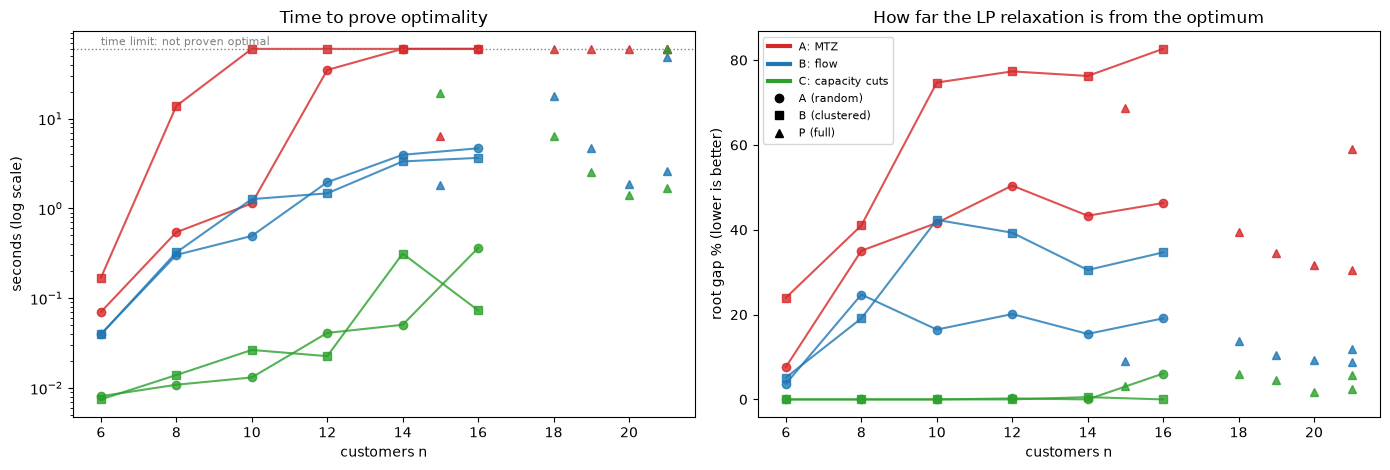

In [13]:
colors = {"A: MTZ": "#d62728", "B: flow": "#1f77b4", "C: capacity cuts": "#2ca02c"}
markers = {"A (random)": "o", "B (clustered)": "s", "P (full)": "^"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for (form, fam), g in df.groupby(["formulation", "family"]):
    g = g.sort_values("n")
    t = g["seconds"].clip(upper=TIME_LIMIT)
    axes[0].plot(g["n"], t, marker=markers[fam], color=colors[form], alpha=0.8,
                 ls="-" if fam != "P (full)" else "none")
    axes[1].plot(g["n"], g["root gap %"], marker=markers[fam], color=colors[form], alpha=0.8,
                 ls="-" if fam != "P (full)" else "none")
axes[0].axhline(TIME_LIMIT, color="grey", ls=":", lw=1)
axes[0].text(6, TIME_LIMIT * 1.1, "time limit: not proven optimal", fontsize=8, color="grey")
axes[0].set(yscale="log", xlabel="customers n", ylabel="seconds (log scale)",
            title="Time to prove optimality")
axes[1].set(xlabel="customers n", ylabel="root gap % (lower is better)",
            title="How far the LP relaxation is from the optimum")
handles = [plt.Line2D([], [], color=c, lw=3, label=f) for f, c in colors.items()]
handles += [plt.Line2D([], [], color="k", marker=m, ls="none", label=f) for f, m in markers.items()]
axes[1].legend(handles=handles, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

**What the results show.**

- **A (MTZ) collapses quickly.** It proves optimality on only 7 of the 18 instances. On random
  customers it reaches $n = 12$ (35 s) and then stops; on clustered customers it already needs
  14 s at $n = 8$ and fails from $n = 10$. Its root gap is huge (48 percent on average, up to
  83 percent): the relaxation knows almost nothing about the real cost, so branch and bound has to
  explore an enormous tree.
- **B (flow) is the only one that proves all 18 optima**, with a median of 1.9 s and a worst case
  of 48 s on `P-n22-k8`. Its root gap (19 percent on average) is much smaller than A's, which
  explains why it scales so much better with the same solver.
- **C (capacity cuts) has by far the tightest relaxation** (1.7 percent root gap on average, never
  more than 6.1 percent) and is the fastest on the A and B families (under half a second). But it
  slows down on `P-n16-k8` (19.5 s, 71 solver calls) and **fails** on `P-n22-k8`. These are the two
  instances with 8 trucks and 2 to 3 customers each (section 2): the integer solutions keep
  combining customers into overloaded routes, each one gives a new cut, and because PuLP has no
  "lazy constraint" callback, every round restarts branch and bound from scratch. This is the
  packing side of the problem, the bin packing remark of section 6, showing up in practice.

The left plot also shows the general trend that section 6 predicted: whatever the formulation,
time grows very fast with $n$; better formulations only push the wall further.

### 9.2 Summary per formulation

In [14]:
summary = df.groupby("formulation").agg(
    proven_optimal=("solved", "sum"),
    instances=("solved", "size"),
    median_seconds=("seconds", "median"),
    mean_root_gap=("root gap %", "mean"),
    max_root_gap=("root gap %", "max"),
    largest_n_proven=("n", lambda s: s[df.loc[s.index, "solved"]].max()),
)
summary["proven %"] = 100 * summary["proven_optimal"] / summary["instances"]
summary

,proven_optimal,instances,median_seconds,mean_root_gap,max_root_gap,largest_n_proven,proven %
formulation,,,,,,,
A: MTZ,7,18,60.03,48.03,82.65,15,38.89
B: flow,18,18,1.92,18.55,42.33,21,100.00
C: capacity cuts,17,18,0.06,1.70,6.09,21,94.44


In [15]:
size = df[df["instance"].eq(P[0].name)].set_index("formulation")[
    ["variables", "constraints", "rounds", "seconds", "root gap %"]]
print(f"Model size on {P[0].name} (n = {P[0].n_customers}):")
size

Model size on P-n16-k8 (n = 15):


,variables,constraints,rounds,seconds,root gap %
formulation,,,,,
A: MTZ,255,242,1,6.43,68.76
B: flow,465,497,1,1.84,9.12
C: capacity cuts,240,162,71,19.45,3.22


**Size against strength.** The small table on `P-n16-k8` shows the trade off clearly. B is the
largest model (about twice A), yet it is the fastest here, because a model with more constraints
can describe the problem more *precisely* (root gap 9 percent instead of 69 percent). C is the
smallest model in the end (only the useful cuts were added), with the best bound, but it pays with
71 calls to the solver.

**Validation.** Every solution returned by every formulation passed the independent feasibility
check, all formulations agree on every optimum, and on the six complete P instances our optimum
is **exactly the published one** (table of section 8.2). We can therefore trust that the model is
written correctly, which is the main goal of this deliverable.

### 9.3 Our choice

**We choose candidate B, the single-commodity flow formulation, as the ILP of our model.**

1. **Reliability:** it is the only one that proved the optimum on every instance, including the
   tight packing cases where C failed.
2. **Readability and checkability:** it has a polynomial number of constraints, all written in
   section 7.3. The tutor (and any solver) can read the complete model; nothing is generated on
   the fly.
3. **Portability:** it runs on any MIP solver with no custom algorithm around it.

**We keep C as a tool, not as the model.** Its relaxation gives by far the best **lower bounds**
(within 2 percent of the optimum on average). In the final deliverable, on instances too large to
solve exactly, these bounds will tell us how far the metaheuristic can be from the optimum. A
proper branch and cut (cuts added inside the solver's tree, with exact separation) would probably
make C the fastest overall, but that is beyond what an off-the-shelf modeling library offers.

**We drop A.** It is the formulation found in most textbooks and the one we started with
(`docs/content/technical/ilp-model.md`), but the experiment shows its relaxation is too weak to
be useful beyond about 10 customers.

## 10. Does the model hold with time windows? (Level A)

### 10.1 The extension

To the chosen model we add $t_i \ge 0$, the service start time at node $i$:

$$
\begin{aligned}
& t_j \ \ge\ t_i + s_i + c_{ij} - M_{ij}\,(1 - x_{ij}) && \forall i \in V,\ j \in V^+,\ i \neq j && \text{(7) time propagation}\\
& e_i \le t_i \le l_i && \forall i \in V && \text{(8) windows}\\
& t_i + s_i + c_{i0} \le l_0 + M_{i0}\,(1 - x_{i0}) && \forall i \in V^+ && \text{(9) back before the depot closes}
\end{aligned}
$$

with the smallest valid constants $M_{ij} = \max(0,\ l_i + s_i + c_{ij} - e_j)$ and
$M_{i0} = \max(0,\ l_i + s_i + c_{i0} - l_0)$: when $x_{ij} = 0$ the constraint is switched off,
and a smaller $M$ keeps the relaxation tighter. **Waiting** is built in: (7) is an inequality,
so service may start after the arrival, while (8) never lets it start before $e_j$. In the code,
`solve_cvrptw` adds (7) to (9) to the formulation chosen in section 9.3 (B: core (1) to (4) plus
the flow constraints (5B) and (6B)). With time windows, (7) alone already forbids loops of
customers; the flow still handles capacity and, as for the CVRP, keeps the relaxation tight
(on the full C101 its LP bound is about twice the one obtained with MTZ).

### 10.2 Test on Solomon C101

We solve the first $n$ customers of C101, then the complete instance, and compare with the same
customers solved **without** windows, to measure what the windows cost.

In [16]:
rows, solutions = [], {}
for n in [10, 15, 20, 25, 30, 40, 50, 100]:
    inst = truncate(C101, n) if n < C101.n_customers else C101
    with_tw = solve_cvrptw(inst, time_limit=TIME_LIMIT)
    no_tw = solve_cvrp_flow(inst, time_limit=TIME_LIMIT)
    solutions[n] = (inst, with_tw.solution, no_tw.solution)
    rows.append({
        "n": n,
        "status": with_tw.status,
        "seconds": with_tw.seconds,
        "cost with windows": with_tw.objective,
        "trucks": len(with_tw.solution),
        "feasible": with_tw.solution.is_feasible(inst),
        "cost without windows": no_tw.objective,
        "status without": no_tw.status,
        # only meaningful when the problem without windows was solved to optimality
        "price of windows %": 100 * (with_tw.objective - no_tw.objective) / no_tw.objective
        if no_tw.status == "Optimal" else np.nan,
        "late routes if windows ignored": sum(
            not is_route_tw_feasible(r, inst) for r in no_tw.solution.routes),
    })
tw_table = pd.DataFrame(rows).set_index("n")
tw_table

,status,seconds,cost with windows,trucks,feasible,cost without windows,status without,price of windows %,late routes if windows ignored
n,,,,,,,,,
10,Optimal,0.01,58.33,1,True,55.29,Optimal,5.49,1
15,Optimal,0.03,142.14,2,True,133.36,Optimal,6.59,2
20,Optimal,0.05,175.37,3,True,158.91,Optimal,10.36,2
25,Optimal,0.07,191.81,3,True,187.45,Optimal,2.33,3
30,Optimal,0.10,206.18,3,True,201.81,Optimal,2.16,2
40,Optimal,0.17,344.63,5,True,331.02,TimeLimit,NaN,4
50,Optimal,0.28,363.25,5,True,370.71,TimeLimit,NaN,4
100,Optimal,1.89,828.94,10,True,886.99,TimeLimit,NaN,10


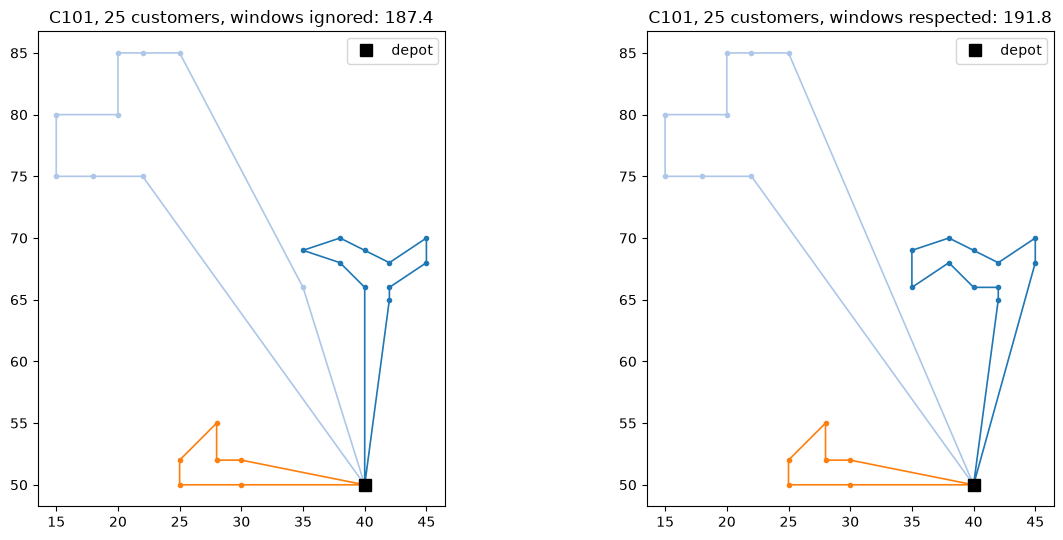

windows ignored -> ['routes violating time windows: [0, 1, 2]']
windows respected -> feasible


In [17]:
inst, sol_tw, sol_free = solutions[25]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_routes(inst, sol_free, ax=axes[0],
            title=f"C101, 25 customers, windows ignored: {sol_free.cost(inst):.1f}")
plot_routes(inst, sol_tw, ax=axes[1],
            title=f"C101, 25 customers, windows respected: {sol_tw.cost(inst):.1f}")
plt.tight_layout()
plt.show()
print("windows ignored ->", sol_free.violations(inst))
print("windows respected ->", sol_tw.violations(inst) or "feasible")

**What the results show.**

- **The extension is correct.** Every solution respects the windows (checked independently with
  `route_schedule`), and on the **complete C101 (100 customers)** the solver proves the optimum
  828.94 in a few seconds, the value reported in the literature for exact distances.
- **Windows matter.** When the same customers are routed while ignoring the windows, *every*
  instance has late routes (right column): a plan that is shorter on paper but cannot be driven.
  On instances where both versions were solved to optimality ($n \le 30$), respecting the windows
  costs 2 to 10 percent more travel time.
- **A surprise: the windows made the problem easier.** The CVRPTW was solved to optimality up to
  100 customers in a few seconds, while the same customers *without* windows could not be proven
  optimal within 60 s from $n = 40$ (`status without`; the price is left blank there, since a
  non-optimal reference would be misleading). C101 has narrow windows on clustered customers, so
  most orders are impossible and the solver can discard them immediately. Instances with wide
  windows (Solomon R and RC sets) are known to be much harder; testing them is part of the
  experimental study.

## 11. Conclusion

### What we deliver

The final output of this notebook is a **validated mathematical model** of CesiCDP's delivery
problem:

1. **Data** (section 3): a complete directed graph built from the road network, with travel times
   $c_{ij}$, demands $q_i$, capacity $Q$, fleet $K$ and, at Level A, windows $[e_i, l_i]$ and
   service times $s_i$, loaded from standard benchmarks.
2. **Problem** (sections 4 and 5): the CVRP, minimizing total travel time, extended with time
   windows (CVRPTW) where waiting is allowed.
3. **Complexity** (section 6): CVRP and CVRPTW are NP-hard (Hamiltonian cycle to TSP to CVRP to
   CVRPTW).
4. **ILP** (sections 7 to 10): the two-index **flow formulation** (B), chosen after testing three
   candidates on 18 instances, with its time window extension; the capacity cut formulation (C)
   kept as a lower bound generator.

**How we know it is right.** The models agree with brute force on the toy instance, return only
feasible routes, find the published optimum on all six complete P instances, and the optimum of
the 100-customer C101 instance with time windows.

### What we learned

- The **choice of formulation matters as much as the solver**: on the same instances and the same
  solver, the weakest formulation (A) proved 7 optima out of 18, the chosen one (B) all 18. The
  quality of the LP relaxation (root gap) explains the difference.
- The CVRP is hard for **two reasons**, routing and packing, and both are visible in the data:
  times explode with $n$, and the instances with many small routes were the hardest for C.
- Constraints can **help** an exact method: tight time windows shrink the space of feasible routes.

### Review of the class hypotheses

| Hypothesis (from the kickoff) | Verdict | Evidence |
| --- | --- | --- |
| The problem is in NP | **Confirmed**, and more: it is NP-hard (its decision version is NP-complete) | section 6 |
| It has polynomial complexity | **Refuted** unless P = NP; solve times grow explosively with $n$ | sections 6 and 9 |
| It can be solved with linear programming | **Partly**: an *integer* LP solves it exactly, but only for small $n$ (about 20 customers in a minute for the CVRP); the LP relaxation alone only gives a lower bound | sections 8 and 9 |
| The solution is a Hamiltonian cycle | **Only with one truck**; in general it is a set of cycles sharing the depot | section 6, step 3 |

### Limits of this study and next steps

- **Exact methods stop early.** About 20 customers within a minute for the CVRP, while CesiCDP's
  target is thousands. This is the reason for the **metaheuristic** of the next deliverable; the
  exact optima found here will serve as ground truth to measure its gap.
- **Small experiment.** One time limit, one machine, 18 CVRP instances and one CVRPTW instance. The
  experimental study will cover at least 20 instances of different families, including wide time
  windows, with a proper statistical protocol.
- **Our version of C is simplified** (heuristic separation, no callback); its failure on tight
  packing instances is partly a limit of the implementation, not only of the formulation.
- **Euclidean distances, no traffic.** Real road travel times and time-dependent speeds
  (section 4) remain extensions.

### Points to validate with the tutor

1. **Fleet:** $K$ is an upper bound on the number of routes (constraint (3) is $\le$).
2. **Objective at Level A:** total travel time, waiting allowed and not counted.
3. **Complexity proof:** the chain HC $\le_p$ TSP $\le_p$ CVRP $\le_p$ CVRPTW, with both
   directions of each reduction.
4. **ILP:** the choice of formulation (section 9.3) and the big-$M$ values of the time windows.
5. **Traffic per time slot:** treated as an extension rather than in the base model.

## 12. References

1. Dantzig, G. B., Ramser, J. H. (1959). The Truck Dispatching Problem. *Management Science*,
   6(1), 80 to 91.
2. Toth, P., Vigo, D. (eds.) (2014). *Vehicle Routing: Problems, Methods, and Applications*,
   2nd ed. SIAM, MOS-SIAM Series on Optimization.
3. Karp, R. M. (1972). Reducibility among combinatorial problems. In *Complexity of Computer
   Computations*, Plenum, 85 to 103.
4. Garey, M. R., Johnson, D. S. (1979). *Computers and Intractability: A Guide to the Theory of
   NP-Completeness*. W. H. Freeman.
5. Miller, C. E., Tucker, A. W., Zemlin, R. A. (1960). Integer programming formulation of
   traveling salesman problems. *Journal of the ACM*, 7(4), 326 to 329.
6. Gavish, B., Graves, S. C. (1978). The travelling salesman problem and related problems.
   Working paper GR-078-78, Operations Research Center, MIT.
7. Laporte, G., Nobert, Y., Desrochers, M. (1985). Optimal routing under capacity and distance
   restrictions. *Operations Research*, 33(5), 1050 to 1073.
8. Savelsbergh, M. W. P. (1985). Local search in routing problems with time windows. *Annals of
   Operations Research*, 4, 285 to 305.
9. Solomon, M. M. (1987). Algorithms for the Vehicle Routing and Scheduling Problems with Time
   Window Constraints. *Operations Research*, 35(2), 254 to 265.
10. Augerat, P., Belenguer, J. M., Benavent, E., Corberan, A., Naddef, D., Rinaldi, G. (1995).
    Computational results with a branch and cut code for the capacitated vehicle routing
    problem. Research report, IMAG. (Instance sets A, B and P.)
11. Ichoua, S., Gendreau, M., Potvin, J.-Y. (2003). Vehicle dispatching with time-dependent travel
    times. *European Journal of Operational Research*, 144(2), 379 to 396.
12. Huangfu, Q., Hall, J. A. J. (2018). Parallelizing the dual revised simplex method.
    *Mathematical Programming Computation*, 10(1), 119 to 142. (HiGHS solver.)
13. CVRPLIB, instances and best known solutions: https://galgos.inf.puc-rio.br/cvrplib/